# Crocs (CROX): Python analysis

The Python side of the project. It works alongside the Excel model (`CROX_Valuation_Model.xlsx`, in the same folder) and the report:

1. **SEC data** - Crocs' financials pulled from SEC XBRL and tied to the model's Hist sheet
2. **Cost of capital** - regression and bottom-up betas, CAPM and WACC
3. **Relative value** - forward P/E regression separating the India premium from growth
4. **DCF check** - an independent DCF on the model's drivers, reconciled to the Excel value
5. **Risk** - 10,000-path Monte Carlo with a fashion-fade regime, and a tornado
6. **Share price** - 12-month performance vs the S&P 500

Requirements: `pip install pandas numpy matplotlib openpyxl statsmodels yfinance`. Sections 1-2 download data from SEC EDGAR and Yahoo Finance.

In [1]:
import json
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
import statsmodels.api as sm
import yfinance as yf

MODEL = "CROX_Valuation_Model.xlsx"
VALUATION_DATE = "2026-09-30"
SEC_USER_AGENT = "CROX research research@example.com"   # SEC asks for a name and e-mail address here
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


class Workbook:
    """Named cells and rows (by label) from the Excel model, using the values Excel saved with the file."""

    def __init__(self, path):
        self.wb = openpyxl.load_workbook(path, data_only=True)
        self.names = {}
        for name, dn in self.wb.defined_names.items():
            sheet, cell = next(dn.destinations)
            self.names[name] = self.wb[sheet][cell.replace("$", "")].value

    def __getitem__(self, name):
        return self.names[name]

    def series(self, sheet, label, offset=0):
        ws = self.wb[sheet]
        years = {int(c.value[2:6]): c.column for c in ws[4] if isinstance(c.value, str) and c.value.startswith("FY")}
        row = next(c.row for c in ws["B"] if isinstance(c.value, str) and c.value.strip() == label) + offset
        return pd.Series({y: ws.cell(row, col).value for y, col in years.items()}, dtype=float)


xl = Workbook(MODEL)
print(f"Excel model: {xl['Rating']}, price target ${xl['PriceTarget']:.0f}, Base DCF ${xl['ValuePerShare']:.2f}, "
      f"WACC {xl['WACC']:.2%}")

Excel model: BUY, price target $190, Base DCF $222.99, WACC 9.53%


## 1. SEC data: historical financials

Annual values from Crocs' 10-K filings (XBRL company facts): 12-month periods or year-end balances, the latest filing winning when a figure is restated. The model's Hist sheet should match them, and the balance sheet should balance.

In [2]:
req = urllib.request.Request("https://data.sec.gov/api/xbrl/companyfacts/CIK0001334036.json",
                             headers={"User-Agent": SEC_USER_AGENT})
facts = json.load(urllib.request.urlopen(req, timeout=60))["facts"]["us-gaap"]


def annual(*tags):
    """FY2021-FY2025 values in US$m; later tags only fill years the earlier ones miss."""
    out = {}
    for tag in tags:
        best = {}
        for r in facts.get(tag, {}).get("units", {}).get("USD", []):
            if r.get("form") != "10-K" or not r["end"].endswith("12-31"):
                continue
            if "start" in r and not 350 <= (pd.Timestamp(r["end"]) - pd.Timestamp(r["start"])).days <= 380:
                continue
            y = int(r["end"][:4])
            if y not in best or r["filed"] > best[y][0]:
                best[y] = (r["filed"], r["val"] / 1e6)
        for y, (_, v) in best.items():
            out.setdefault(y, v)
    return pd.Series(out).reindex(range(2021, 2026))


sec = pd.DataFrame({
    "Revenue": annual("RevenueFromContractWithCustomerExcludingAssessedTax", "Revenues"),
    "Gross profit": annual("GrossProfit"),
    "Operating income (EBIT)": annual("OperatingIncomeLoss"),
    "Net income": annual("NetIncomeLoss"),
    "Total assets": annual("Assets"),
    "Total liabilities": annual("Liabilities"),
    "Total stockholders' equity": annual("StockholdersEquity"),
    "Cash from operations": annual("NetCashProvidedByUsedInOperatingActivities"),
}).T
sec.round(1)

,2021,2022,2023,2024,2025
Revenue,2313.4,3555.0,3962.3,4102.1,4040.6
Gross profit,1420.2,1860.3,2210.0,2410.3,2357.1
Operating income (EBIT),683.1,850.8,1036.8,1021.9,149.5
Net income,725.7,540.2,792.6,950.1,-81.2
Total assets,1545.1,4501.8,4643.8,4812.2,4174.8
Total liabilities,1531.0,3683.9,3189.9,2976.4,2881.5
Total stockholders' equity,14.1,817.9,1453.9,1835.7,1293.3
Cash from operations,567.2,603.1,930.4,992.5,710.4


In [3]:
hist = pd.DataFrame({lab: xl.series("Hist", lab)[list(sec.columns)] for lab in sec.index}).T
check = pd.DataFrame({
    "max |SEC - Hist sheet|": (sec - hist).abs().max(axis=1),
    "balance check (A - L - E)": np.nan})
check.loc["Total assets", "balance check (A - L - E)"] = (
    sec.loc["Total assets"] - sec.loc["Total liabilities"] - sec.loc["Total stockholders' equity"]).abs().max()
check.round(3)

,max |SEC - Hist sheet|,balance check (A - L - E)
Revenue,0.0,NaN
Gross profit,0.0,NaN
Operating income (EBIT),0.0,NaN
Net income,0.0,NaN
Total assets,0.0,0.0
Total liabilities,0.0,NaN
Total stockholders' equity,0.0,NaN
Cash from operations,0.0,NaN


## 2. Cost of capital

- **Regression beta:** 5 years of weekly CROX returns against the S&P 500, Blume-adjusted.
- **Bottom-up beta:** each peer's beta against its home index, unlevered at its own debt / equity (Hamada), developed-market median relevered at Crocs' debt / equity.
- **WACC:** the average of the two betas, CAPM on the 10-year Treasury, BB-rated cost of debt, market-value weights.

In [4]:
COMPS = pd.DataFrame({  # Yahoo Finance snapshot at 30-Sep-2026 (US$m), as on the Comps sheet
    "CROX": ["Crocs, Inc.", "US", 5683.9, 1230.9, 7.93, 0.0241, 0.2422],
    "DECK": ["Deckers Outdoor", "US", 10638.5, 0.0, 9.38, 0.0723, 0.1523],
    "SHOO": ["Steven Madden", "US", 3267.0, 234.2, 16.07, 0.0819, 0.0669],
    "WWW": ["Wolverine World Wide", "US", 1559.3, 621.7, 10.27, 0.0583, 0.0985],
    "BIRK": ["Birkenstock", "Europe", 5335.9, 1266.2, 11.69, 0.1378, 0.2897],
    "ONON": ["On Holding", "Europe", 9864.3, 0.0, 14.41, 0.1886, 0.1402],
    "DOCS.L": ["Dr. Martens", "UK", 889.9, 331.2, 11.54, 0.0487, 0.1565],
    "METROBRAND.NS": ["Metro Brands", "India", 2394.6, 0.0, 40.57, 0.1623, 0.1800],
    "RELAXO.NS": ["Relaxo Footwears", "India", 756.5, 0.0, 29.30, 0.0940, 0.0965],
    "CAMPUS.NS": ["Campus Activewear", "India", 666.2, 3.8, 30.51, 0.1279, 0.0832],
    "BATAINDIA.NS": ["Bata India", "India", 830.0, 0.0, 29.04, 0.0834, 0.1056],
}, index=["name", "region", "mcap_usd", "debt_usd", "forward_pe", "g_next", "op_margin"]).T
for c in COMPS.columns[2:]:
    COMPS[c] = COMPS[c].astype(float)
HOME = {"US": "^GSPC", "Europe": "^GSPC", "UK": "^FTSE", "India": "^NSEI"}
TAX = {"US": 0.25, "Europe": 0.25, "UK": 0.25, "India": 0.252}

px = yf.download(list(COMPS.index) + ["^GSPC", "^FTSE", "^NSEI", "^TNX"], start="2021-09-01", end="2026-10-01",
                 auto_adjust=True, progress=False)["Close"]
CLOSE_30SEP = {"CROX": 118.545, "DECK": 78.12, "SHOO": 44.645, "WWW": 18.985, "BIRK": 32.3, "ONON": 29.52,
               "DOCS.L": 70.1, "METROBRAND.NS": 841.75, "RELAXO.NS": 291.2, "CAMPUS.NS": 208.83,
               "BATAINDIA.NS": 618.75, "^GSPC": 7709.83, "^FTSE": 10606.0, "^NSEI": 22620.45, "^TNX": 5.283}
for t, v in CLOSE_30SEP.items():                          # valuation-date closes used in the model
    px.loc[VALUATION_DATE, t] = v
rf = px.loc[VALUATION_DATE, "^TNX"] / 100                 # 10-year US Treasury yield


def beta(stock, index, years=5.0):
    s = pd.concat([px[stock], px[index]], axis=1, keys=["s", "m"]).dropna()
    s = s[s.index >= s.index[-1] - pd.DateOffset(days=int(365.25 * years))]
    r = s.resample("W-FRI").last().pct_change().dropna()
    fit = sm.OLS(r["s"], sm.add_constant(r["m"])).fit()
    return float(fit.params["m"]), float(fit.rsquared), r


b_raw, r2, crox_weekly = beta("CROX", "^GSPC")
peers = COMPS.drop("CROX").copy()
spans = {t: (px[t].dropna().index[-1] - px[t].dropna().index[0]).days / 365.25 for t in peers.index}
peers["levered_beta"] = [beta(t, HOME[peers.loc[t, "region"]], min(5.0, spans[t]))[0] for t in peers.index]
peers["unlevered_beta"] = peers.levered_beta / (1 + (1 - peers.region.map(TAX)) * peers.debt_usd / peers.mcap_usd)
peers[["name", "region", "levered_beta", "unlevered_beta"]].round(2)

,name,region,levered_beta,unlevered_beta
DECK,Deckers Outdoor,US,1.03,1.03
SHOO,Steven Madden,US,1.18,1.12
WWW,Wolverine World Wide,US,1.35,1.04
BIRK,Birkenstock,Europe,1.19,1.01
ONON,On Holding,Europe,1.79,1.79
DOCS.L,Dr. Martens,UK,1.34,1.04
METROBRAND.NS,Metro Brands,India,0.72,0.72
RELAXO.NS,Relaxo Footwears,India,0.87,0.87
CAMPUS.NS,Campus Activewear,India,0.92,0.92
BATAINDIA.NS,Bata India,India,1.11,1.11


In [5]:
ERP, BB_SPREAD, TAX_US, SHARES = 0.0423, 0.0225, 0.25, 47.945
price, debt = xl["SharePrice"], xl["DebtFace"]   # share price at the valuation date, as in the model
mcap = price * SHARES
blume = 0.67 * b_raw + 0.33
bottom_up = peers.loc[peers.region != "India", "unlevered_beta"].median() * (1 + (1 - TAX_US) * debt / mcap)
beta_sel = (blume + bottom_up) / 2
ke, kd, wd = rf + beta_sel * ERP, rf + BB_SPREAD, debt / (debt + mcap)
wacc = (1 - wd) * ke + wd * kd * (1 - TAX_US)
pd.Series({"Risk-free rate": rf, "Regression beta (raw)": b_raw, "Regression beta (Blume)": blume,
           "R-squared": r2, "Bottom-up beta (relevered)": bottom_up, "Selected beta": beta_sel,
           "Cost of equity": ke, "Pre-tax cost of debt": kd, "Debt weight": wd,
           "WACC (Python)": wacc, "WACC (Excel model)": xl["WACC"]}).round(4).to_frame("value")

,value
Risk-free rate,0.0528
Regression beta (raw),1.3132
Regression beta (Blume),1.2098
R-squared,0.1624
Bottom-up beta (relevered),1.2270
Selected beta,1.2184
Cost of equity,0.1044
Pre-tax cost of debt,0.0753
Debt weight,0.1901
WACC (Python),0.0953


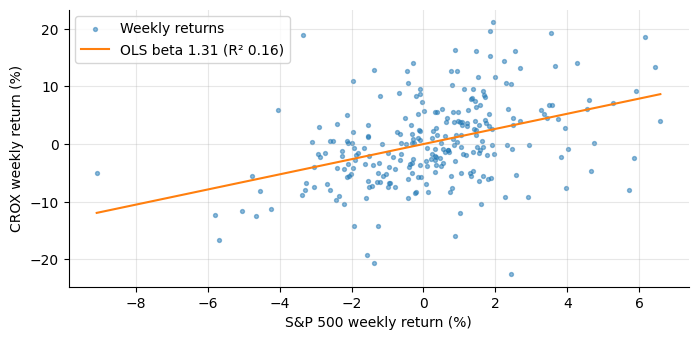

In [6]:
xs = np.linspace(crox_weekly.m.min(), crox_weekly.m.max(), 10)
plt.scatter(crox_weekly.m * 100, crox_weekly.s * 100, s=8, alpha=0.5, label="Weekly returns")
plt.plot(xs * 100, b_raw * xs * 100, color="C1", label=f"OLS beta {b_raw:.2f} (R² {r2:.2f})")
plt.xlabel("S&P 500 weekly return (%)"); plt.ylabel("CROX weekly return (%)"); plt.legend(); plt.show()

## 3. Relative value: the India premium

Forward P/E regressed on next-year revenue growth, operating margin and an India dummy across the ten peers. The dummy measures how much of the Indian multiples growth and margins do not explain; the fitted value shows whether Crocs is mispriced for its own growth.

R² 0.92 | India premium 19.1 turns (s.e. 2.7) | Crocs fitted P/E 8.2x vs actual 7.9x


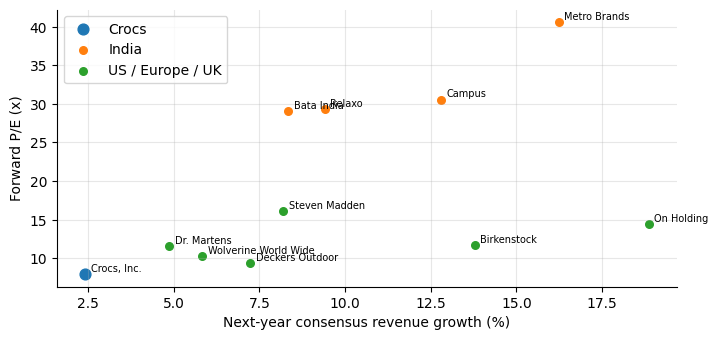

In [7]:
X = pd.DataFrame({"g_next": peers.g_next, "op_margin": peers.op_margin, "india": (peers.region == "India").astype(float)})
fit = sm.OLS(peers.forward_pe, sm.add_constant(X)).fit()
crox_x = pd.DataFrame({"const": [1.0], "g_next": [COMPS.loc["CROX", "g_next"]],
                       "op_margin": [COMPS.loc["CROX", "op_margin"]], "india": [0.0]})
print(f"R² {fit.rsquared:.2f} | India premium {fit.params['india']:.1f} turns (s.e. {fit.bse['india']:.1f}) | "
      f"Crocs fitted P/E {fit.predict(crox_x)[0]:.1f}x vs actual {COMPS.loc['CROX', 'forward_pe']:.1f}x")
for region, g in COMPS.assign(group=np.where(COMPS.index == "CROX", "Crocs", np.where(COMPS.region == "India", "India", "US / Europe / UK"))).groupby("group"):
    plt.scatter(g.g_next * 100, g.forward_pe, s=60 if region == "Crocs" else 30, label=region)
    for t, r in g.iterrows():
        plt.annotate(r["name"].replace(" Footwears", "").replace(" Activewear", ""), (r.g_next * 100, r.forward_pe),
                     xytext=(4, 2), textcoords="offset points", fontsize=7)
plt.xlabel("Next-year consensus revenue growth (%)"); plt.ylabel("Forward P/E (x)"); plt.legend(); plt.show()

## 4. DCF check: an independent Python DCF on the model's drivers

The forecast drivers (Inputs sheet), FY2025 opening balances (Hist sheet) and discount-rate inputs (named cells) are read from the workbook; the free cash flows and DCF are rebuilt here and compared with the value Excel calculated.

In [8]:
FC_YEARS = list(range(2026, 2036))
LEAVES = ["crocs_na_whsl", "crocs_na_dtc", "crocs_intl_whsl", "crocs_intl_dtc", "hd_whsl", "hd_dtc"]
TAU = np.array([0.25] + [float(y - 2026) for y in FC_YEARS[1:]])   # mid-period years from 30-Jun-2026
SCENARIO_DRIVERS = {  # Inputs sheet: label row, then Base / Bull / Bear rows
    "g_crocs_na_whsl": "Crocs North America wholesale growth", "g_crocs_na_dtc": "Crocs North America DTC growth",
    "g_crocs_intl_whsl": "Crocs International wholesale growth", "g_crocs_intl_dtc": "Crocs International DTC growth",
    "g_hd_whsl": "HEYDUDE wholesale growth", "g_hd_dtc": "HEYDUDE DTC growth",
    "gm_crocs": "Crocs brand gross margin", "gm_hd": "HEYDUDE gross margin",
    "sga_crocs": "Crocs brand SG&A % revenue", "sga_hd": "HEYDUDE SG&A % revenue",
    "corp_pct": "Corporate / unallocated costs % revenue", "charges_pct": "Restructuring & other charges % revenue",
    "dso": "Receivable days (DSO, on revenue)", "dio": "Inventory days (DIO, on COGS)",
    "dpo": "Payable days (DPO, on COGS)", "capex_pct": "Capex % revenue"}
SINGLE_DRIVERS = {
    "accrued_pct": "Accrued expenses % revenue", "prepaid_pct": "Prepaid & other current assets % revenue",
    "dep_rate": "Depreciation % beginning net PP&E", "lease_pct": "Operating lease liabilities % revenue",
    "etr_cash": "Cash / adjusted tax rate", "amort_sched": "Amortisation of acquired & existing intangibles"}
HIST = {
    "crocs_na_whsl": "Crocs - North America - Wholesale", "crocs_na_dtc": "Crocs - North America - DTC",
    "crocs_intl_whsl": "Crocs - International - Wholesale", "crocs_intl_dtc": "Crocs - International - DTC",
    "hd_whsl": "HEYDUDE - Wholesale", "hd_dtc": "HEYDUDE - DTC", "ppe": "PP&E, net", "fin": "of which: finite-lived, net",
    "tax_rec": "Income taxes receivable", "tax_pay": "Income taxes payable", "other_cl": "Other current liabilities",
    "ar": "Accounts receivable", "inv": "Inventories", "prepaid": "Prepaid & other current assets",
    "ap": "Accounts payable", "accrued": "Accrued expenses & other", "lease_cur": "Operating lease liabilities - current",
    "lease_lt": "Operating lease liabilities - non-current", "rou": "Operating lease ROU assets"}

D = {k: xl.series("Inputs", lab, offset=1)[FC_YEARS].fillna(0).values for k, lab in SCENARIO_DRIVERS.items()}  # Base rows
D |= {k: xl.series("Inputs", lab)[FC_YEARS].fillna(0).values for k, lab in SINGLE_DRIVERS.items()}
H = {k: xl.series("Hist", lab)[2025] for k, lab in HIST.items()}
DTA_2035 = xl.series("Tax", "Closing deferred tax assets")[2035]
PARAMS = {"wacc": xl["WACC"], "ke": xl["Ke"], "g": xl["TG_Base"], "tax_tv": xl["TaxTV"], "h2": xl["H2Share"],
          "dta_years": xl["DTAYears"], "debt": xl["DebtFace"], "cash": xl["CashJun"], "utp": xl["UTP"] * xl["UTPPct"],
          "shares": xl["SharesDil"], "roll": xl["RollFwd"]}


def dcf_value(shocks=None, wacc=None, g=None, ke=None):
    """Base-case value per share; shocks shift growth / margin drivers (scalars or one value per path)."""
    s, p, d = shocks or {}, PARAMS, D
    wacc = p["wacc"] if wacc is None else wacc
    ke = p["ke"] if ke is None else ke
    g = p["g"] if g is None else g
    lv = {k: H[k] for k in LEAVES}
    ppe, fin = H["ppe"], H["fin"]
    nwc_prev = H["ar"] + H["inv"] + H["prepaid"] + H["tax_rec"] - H["ap"] - H["accrued"] - H["tax_pay"] - H["other_cl"]
    lease_prev, rou_prev = H["lease_cur"] + H["lease_lt"], H["rou"]
    rou_ratio = rou_prev / lease_prev
    fcff, ebit = [], None
    for i in range(len(FC_YEARS)):
        for k in LEAVES:
            lv[k] = lv[k] * (1 + d["g_" + k][i] + s.get("g_hd" if k.startswith("hd") else "g_crocs", 0.0))
        crocs = lv["crocs_na_whsl"] + lv["crocs_na_dtc"] + lv["crocs_intl_whsl"] + lv["crocs_intl_dtc"]
        hd = lv["hd_whsl"] + lv["hd_dtc"]
        rev = crocs + hd
        gm_c, gm_h = d["gm_crocs"][i] + s.get("gm_crocs", 0.0), d["gm_hd"][i] + s.get("gm_hd", 0.0)
        cogs = crocs * (1 - gm_c) + hd * (1 - gm_h)
        sga = (crocs * (d["sga_crocs"][i] + s.get("sga_crocs", 0.0)) + hd * d["sga_hd"][i]
               + rev * (d["corp_pct"][i] + d["charges_pct"][i]))
        ebit = rev - cogs - sga
        capex = rev * d["capex_pct"][i]
        dep = ppe * d["dep_rate"][i]
        ppe = ppe + capex - dep
        amort = np.minimum(fin, d["amort_sched"][i])
        fin = fin - amort
        nwc = (rev * d["dso"][i] / 365 + cogs * d["dio"][i] / 365 + rev * d["prepaid_pct"][i] + H["tax_rec"]
               - cogs * d["dpo"][i] / 365 - rev * d["accrued_pct"][i] - H["tax_pay"] - H["other_cl"])
        lease = rev * d["lease_pct"][i]
        rou = lease * rou_ratio
        fcff.append(ebit * (1 - d["etr_cash"][i]) + dep + amort - capex + (nwc_prev - nwc)
                    + (lease - rou) - (lease_prev - rou_prev))
        nwc_prev, lease_prev, rou_prev = nwc, lease, rou
    f = np.array(np.broadcast_arrays(*fcff), float)
    f[0] = f[0] * p["h2"]                                            # cash flows from 1-Jul-2026
    pv = (f * (1 + wacc) ** -TAU.reshape(-1, *([1] * (f.ndim - 1)))).sum(axis=0)
    n_end = TAU[-1] + 0.5
    fcff_tv = f[-1] + ebit * (d["etr_cash"][-1] - p["tax_tv"])        # terminal tax normalised
    pv_tv = fcff_tv * (1 + g) / (wacc - g) / (1 + wacc) ** n_end
    pv_dta = DTA_2035 / p["dta_years"] * (1 - (1 + wacc) ** -p["dta_years"]) / wacc / (1 + wacc) ** n_end
    equity = (pv + pv_tv + pv_dta - p["debt"] + p["cash"] - p["utp"]) * (1 + ke) ** p["roll"]
    return equity / p["shares"]


py, ex = float(dcf_value()), xl["ValuePerShare"]
print(f"Base DCF per share - Python ${py:.4f} vs Excel ${ex:.4f} (difference {py - ex:.1e})")

Base DCF per share - Python $222.9883 vs Excel $222.9883 (difference 0.0e+00)


## 5. Risk: Monte Carlo and tornado

Seven drivers are drawn jointly (correlations below), and 30% of paths - the Bear weight - also take a persistent fashion fade, as in 2008. The tornado moves each driver by one standard deviation on its own.

P10 $97 | median $195 | P90 $297 | above price 81% | above target 52% | fade paths median $109

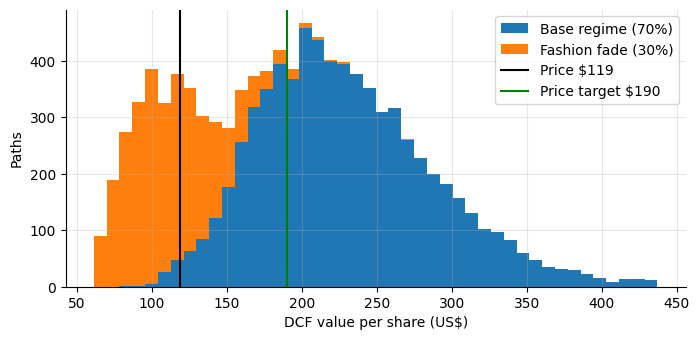

In [9]:
MC_SPEC = {"g_crocs": (0.020, "Crocs brand growth"), "g_hd": (0.040, "HEYDUDE growth"),
           "gm_crocs": (0.015, "Crocs gross margin"), "gm_hd": (0.025, "HEYDUDE gross margin"),
           "sga_crocs": (0.010, "Crocs SG&A %"), "wacc": (0.0075, "WACC"), "g_tv": (0.005, "Terminal growth")}
MC_CORR = {("g_crocs", "gm_crocs"): 0.5, ("g_crocs", "sga_crocs"): -0.3, ("g_hd", "gm_hd"): 0.5,
           ("g_crocs", "g_hd"): 0.4, ("g_crocs", "g_tv"): 0.3}
FADE = {"prob": 0.30, "g_crocs": -0.06, "g_hd": -0.08, "gm_crocs": -0.02, "sga_crocs": 0.01, "g_tv": -0.015}

names = list(MC_SPEC)
C = np.eye(len(names))
for (a, b), r in MC_CORR.items():
    C[names.index(a), names.index(b)] = C[names.index(b), names.index(a)] = r
rng = np.random.default_rng(20260930)
z = rng.standard_normal((10_000, len(names))) @ np.linalg.cholesky(C).T
draws = {nm: z[:, i] * MC_SPEC[nm][0] for i, nm in enumerate(names)}
fade = rng.random(10_000) < FADE["prob"]
for nm in ("g_crocs", "g_hd", "gm_crocs", "sga_crocs", "g_tv"):
    draws[nm] = draws[nm] + np.where(fade, FADE[nm], 0.0)
paths = dcf_value({k: draws[k] for k in ("g_crocs", "g_hd", "gm_crocs", "gm_hd", "sga_crocs")},
                  wacc=PARAMS["wacc"] + draws["wacc"], ke=PARAMS["ke"] + draws["wacc"],
                  g=np.clip(PARAMS["g"] + draws["g_tv"], 0.015, 0.04))
p10, p50, p90 = np.percentile(paths, [10, 50, 90])
print(f"P10 ${p10:.0f} | median ${p50:.0f} | P90 ${p90:.0f} | above price {np.mean(paths > price):.0%} | "
      f"above target {np.mean(paths > xl['PriceTarget']):.0%} | fade paths median ${np.median(paths[fade]):.0f}")

bins = np.linspace(np.percentile(paths, 0.5), np.percentile(paths, 99.5), 45)
plt.hist([paths[~fade], paths[fade]], bins=bins, stacked=True, label=["Base regime (70%)", "Fashion fade (30%)"])
plt.axvline(price, color="k", label=f"Price ${price:.0f}"); plt.axvline(xl["PriceTarget"], color="g", label="Price target $190")
plt.xlabel("DCF value per share (US$)"); plt.ylabel("Paths"); plt.legend(); plt.show()

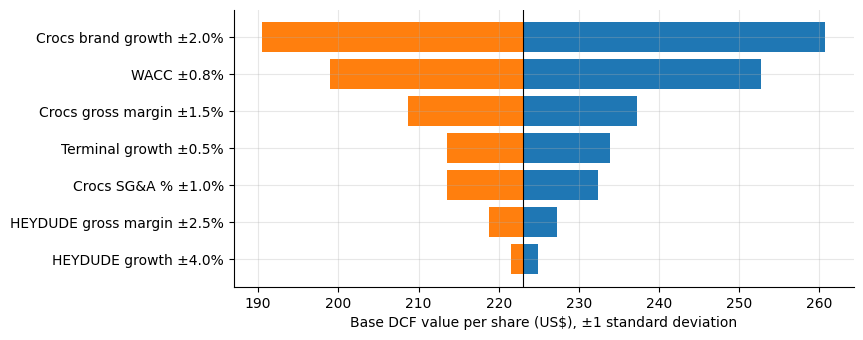

,driver,low,high,range
0,Crocs brand growth ±2.0%,190.5,260.8,70.3
5,WACC ±0.8%,199.0,252.7,53.7
2,Crocs gross margin ±1.5%,208.7,237.2,28.5
6,Terminal growth ±0.5%,213.5,233.9,20.4
4,Crocs SG&A % ±1.0%,213.5,232.4,18.9
3,HEYDUDE gross margin ±2.5%,218.8,227.2,8.5
1,HEYDUDE growth ±4.0%,221.5,224.9,3.4


In [10]:
rows = []
for nm, (sig, label) in MC_SPEC.items():
    lo, hi = [float(dcf_value(wacc=PARAMS["wacc"] + k * sig, ke=PARAMS["ke"] + k * sig) if nm == "wacc" else
                    dcf_value(g=PARAMS["g"] + k * sig) if nm == "g_tv" else dcf_value({nm: k * sig})) for k in (-1, 1)]
    rows.append((f"{label} ±{sig:.1%}", min(lo, hi), max(lo, hi)))
tor = pd.DataFrame(rows, columns=["driver", "low", "high"]).assign(range=lambda t: t.high - t.low).sort_values("range")
plt.barh(tor.driver, tor.high - py, left=py); plt.barh(tor.driver, tor.low - py, left=py)
plt.axvline(py, color="k", lw=0.8); plt.xlabel("Base DCF value per share (US$), ±1 standard deviation"); plt.show()
tor.sort_values("range", ascending=False).round(1)

## 6. Share price: 12 months vs the S&P 500

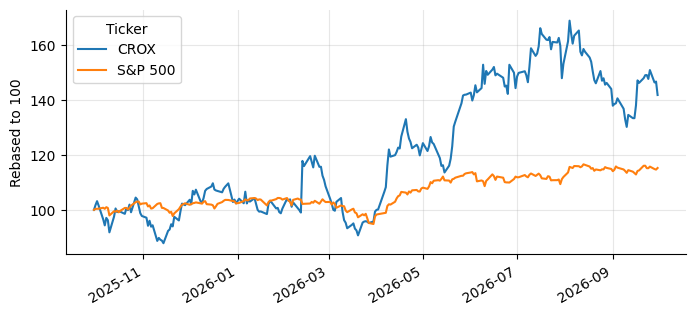

In [11]:
last12 = px[["CROX", "^GSPC"]].dropna().loc["2025-09-30":]
(last12 / last12.iloc[0] * 100).rename(columns={"^GSPC": "S&P 500"}).plot(ylabel="Rebased to 100", xlabel="")
plt.show()